In [1]:

import torch
import torchvision
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
GPU available: Tesla T4
Selected device: cuda


In [2]:

import torchvision.transforms as transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

# Prepare images
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Download training dataset
train_data = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download testing dataset
test_data = CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Select automobile (1) and truck (9)
vehicle_classes = [1, 9]

train_indices = [
    i for i, label in enumerate(train_data.targets)
    if label in vehicle_classes
]

test_indices = [
    i for i, label in enumerate(test_data.targets)
    if label in vehicle_classes
]

train_subset = Subset(train_data, train_indices)
test_subset = Subset(test_data, test_indices)

print("Training images:", len(train_subset))
print("Testing images:", len(test_subset))
print("Classes: Automobile and Truck")



100%|██████████| 170M/170M [05:28<00:00, 520kB/s]


Training images: 10000
Testing images: 2000
Classes: Automobile and Truck


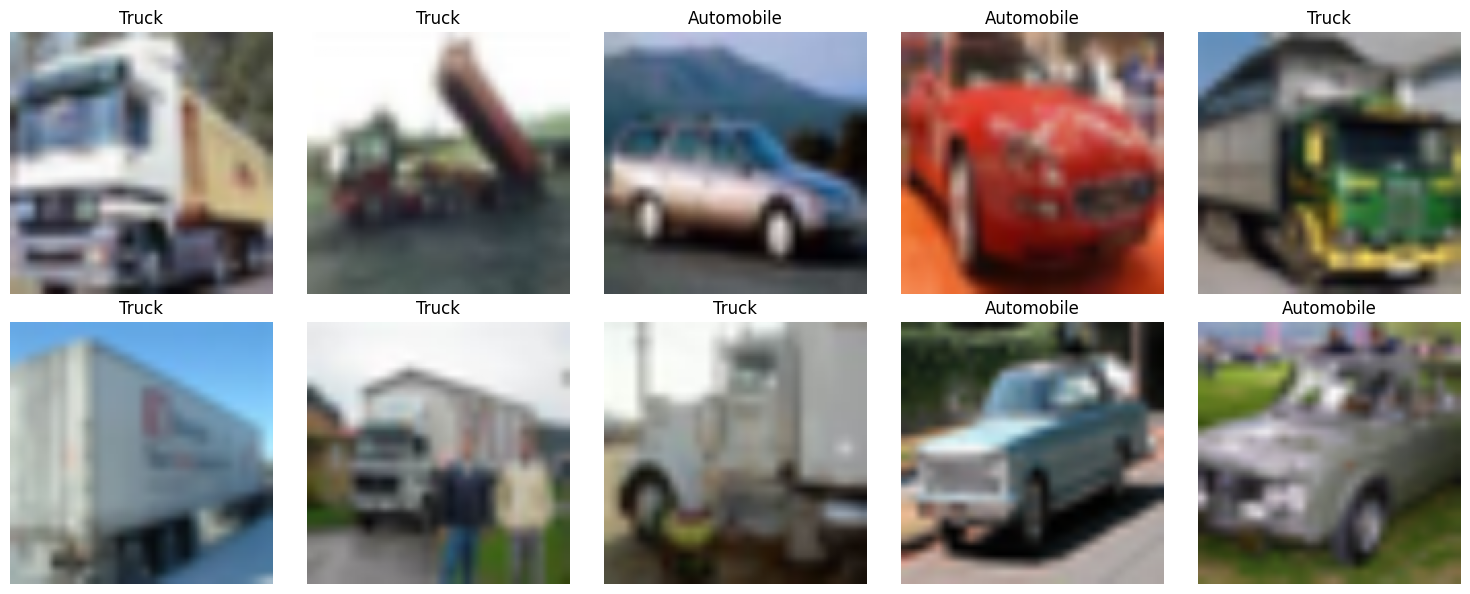

In [3]:

import matplotlib.pyplot as plt

# Class names
class_names = ["Automobile", "Truck"]

# Display 10 sample images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):

    image, label = train_subset[i]

    # Convert tensor to image format
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(class_names[label == 9])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:

from torch.utils.data import Dataset, DataLoader

class VehicleDataset(Dataset):

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, original_label = self.dataset[index]

        # Convert original labels to 0 and 1
        new_label = 0 if original_label == 1 else 1

        return image, new_label


# Prepare datasets
train_vehicle_data = VehicleDataset(train_subset)
test_vehicle_data = VehicleDataset(test_subset)

# Create data loaders
train_loader = DataLoader(
    train_vehicle_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_vehicle_data,
    batch_size=64,
    shuffle=False
)

# Inspect one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())
print("Device:", device)



Image batch shape: torch.Size([64, 3, 128, 128])
Label batch shape: torch.Size([64])
First 10 labels: [0, 0, 1, 0, 0, 0, 1, 1, 0, 0]
Device: cuda


In [5]:

import torch.nn as nn
import torch.nn.functional as F

class RoadVisionCNN(nn.Module):

    def __init__(self):
        super(RoadVisionCNN, self).__init__()

        # First convolution layer
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)

        # Second convolution layer
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Third convolution layer
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # Pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        self.fc1 = nn.Linear(128 * 16 * 16, 256)
        self.fc2 = nn.Linear(256, 2)

        self.dropout = nn.Dropout(0.3)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.fc2(x)

        return x


# Initialize model
model = RoadVisionCNN().to(device)

print(model)
print("\nModel successfully initialized!")
print("Running on:", device)


RoadVisionCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=32768, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)

Model successfully initialized!
Running on: cuda


In [6]:

import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training settings
epochs = 5

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_loss += loss.item()

        # Calculate predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {running_loss/len(train_loader):.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )


Epoch [1/5] Loss: 0.6140 Accuracy: 66.22%
Epoch [2/5] Loss: 0.5548 Accuracy: 71.27%
Epoch [3/5] Loss: 0.4893 Accuracy: 76.53%
Epoch [4/5] Loss: 0.4201 Accuracy: 80.90%
Epoch [5/5] Loss: 0.3419 Accuracy: 85.30%


In [7]:

model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total
average_test_loss = test_loss / len(test_loader)

print("RoadVision AI Evaluation")
print("-------------------------")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Loss: {average_test_loss:.4f}")
print(f"Correct Predictions: {correct}/{total}")


RoadVision AI Evaluation
-------------------------
Test Accuracy: 83.55%
Test Loss: 0.3705
Correct Predictions: 1671/2000


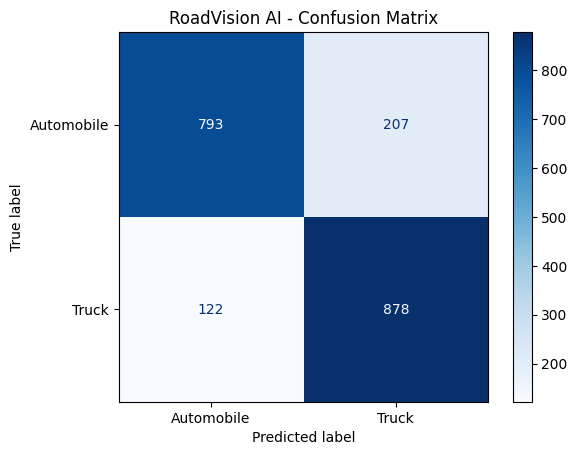

              precision    recall  f1-score   support

  Automobile       0.87      0.79      0.83      1000
       Truck       0.81      0.88      0.84      1000

    accuracy                           0.84      2000
   macro avg       0.84      0.84      0.84      2000
weighted avg       0.84      0.84      0.84      2000



In [8]:

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

# Generate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Automobile", "Truck"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("RoadVision AI - Confusion Matrix")
plt.show()

# Detailed performance report
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Automobile", "Truck"]
))


Saving Screenshot 2026-11-23 120635.png to Screenshot 2026-11-23 120635.png


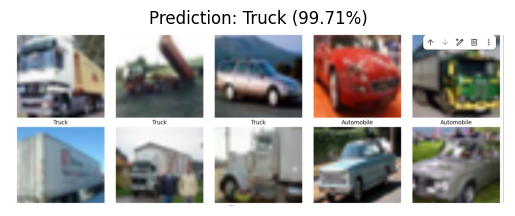

Predicted vehicle: Truck
Confidence: 99.71%


In [9]:

from google.colab import files
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch

# Upload an image
uploaded = files.upload()

# Get uploaded image
image_path = next(iter(uploaded))

# Open image
image = Image.open(image_path).convert("RGB")

# Prepare image
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

input_image = transform(image).unsqueeze(0).to(device)

# Make prediction
model.eval()

with torch.no_grad():
    output = model(input_image)
    probabilities = torch.softmax(output, dim=1)

    confidence, prediction = torch.max(probabilities, 1)

classes = ["Automobile", "Truck"]

predicted_class = classes[prediction.item()]
confidence_score = confidence.item() * 100

# Display result
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class} "
    f"({confidence_score:.2f}%)"
)
plt.show()

print("Predicted vehicle:", predicted_class)
print(f"Confidence: {confidence_score:.2f}%")


In [10]:
torch.save(model.state_dict(), "roadvision_cnn.pth")

print("RoadVision AI model saved successfully!")

RoadVision AI model saved successfully!


In [11]:
from google.colab import files

files.download("roadvision_cnn.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>